# Whisper small.en vs wav2vec2

Frozen raw-ASR results. Running these cells reads existing files and displays local audio; it does not run models, train, call APIs, or upload audio.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Markdown, Image, Audio
ROOT = Path.cwd().resolve()
while not (ROOT / "scripts/compare_asr_backends.py").is_file():
    if ROOT.parent == ROOT: raise RuntimeError("Open this notebook from the MDD workspace")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.report_asr_backends import load_bundle, metric_rows, case_rows, conclusions
OUT = ROOT / 'data/generated/asr-backends-20261023'
bundle = load_bundle(OUT)
manifest, results = bundle["manifest"], bundle["results"]
display(Markdown(f"**{len(manifest['cases'])} recordings; all three backends completed.** Manifest: `{results['manifest_sha256']}`"))

**118 recordings; all three backends completed.** Manifest: `bd2d0cf9abc15d780b833a946684c48fecdad8a7c38c409f2ede426f4d6f433e`

## Group metrics

Micro WER = summed substitutions, deletions and insertions / summed reference words. Strict WER is primary; the secondary score applies the same English number normalization to all models.

In [2]:
metrics = pd.DataFrame(metric_rows(bundle))
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(metrics)
for statement in conclusions(bundle): display(Markdown(statement))

,group,model,cases,strict_word_errors,strict_reference_words,strict_wer,number_normalized_word_errors,number_normalized_reference_words,number_normalized_wer,substitutions,deletions,insertions,exact_matches,inference_seconds,mean_inference_seconds,audio_seconds,real_time_factor
0,saa_external_same_prompt,wav2vec2-base-960h,4,92,276,0.333333,92,276,0.333333,81,10,1,0,12.423,3.105750,103.930572,0.119532
1,saa_external_same_prompt,wav2vec2-vi-en-v1,4,85,276,0.307971,85,276,0.307971,71,13,1,0,11.796,2.949000,103.930572,0.113499
2,saa_external_same_prompt,whisper-small.en,4,31,276,0.112319,21,276,0.076087,28,2,1,0,16.234,4.058500,103.930572,0.156200
3,tlv_previously_observed_heldout,wav2vec2-base-960h,111,436,1023,0.426197,436,1020,0.427451,379,31,26,3,62.034,0.558865,483.237732,0.128372
4,tlv_previously_observed_heldout,wav2vec2-vi-en-v1,111,385,1023,0.376344,386,1020,0.378431,325,36,24,4,49.596,0.446811,483.237732,0.102633
5,tlv_previously_observed_heldout,whisper-small.en,111,284,1023,0.277615,282,1020,0.276471,248,17,19,17,262.295,2.363018,483.237732,0.542787
6,user_development,wav2vec2-base-960h,3,42,80,0.525000,42,77,0.545455,36,4,2,0,3.484,1.161333,30.380250,0.114680
7,user_development,wav2vec2-vi-en-v1,3,43,80,0.537500,43,77,0.558442,35,4,4,0,3.298,1.099333,30.380250,0.108557
8,user_development,whisper-small.en,3,21,80,0.262500,18,77,0.233766,18,1,2,0,8.359,2.786333,30.380250,0.275146


SAA · 4 external speakers, same paragraph: fine-tuning reduced WER by 2.54 percentage points versus its own wav2vec2 base (33.33% → 30.80%; signed relative error reduction 7.6%). Whisper small.en WER is 11.23% in this separate pretrained-model comparison.

TLV · 111 previously observed held-out clips: fine-tuning reduced WER by 4.99 percentage points versus its own wav2vec2 base (42.62% → 37.63%; signed relative error reduction 11.7%). Whisper small.en WER is 27.76% in this separate pretrained-model comparison.

User · 3 development recordings: fine-tuning increased WER by 1.25 percentage points versus its own wav2vec2 base (52.50% → 53.75%; signed relative error reduction -2.4%). Whisper small.en WER is 26.25% in this separate pretrained-model comparison.

Fine-tuning benefit is measured against the same base model. A stronger separate model can still outperform a fine-tuned smaller-data system; this benchmark does not identify which architecture or training-data difference caused the gap.

## Visual comparison

Raw ASR latency excludes model loading and audio decoding; Whisper includes native word timestamps.

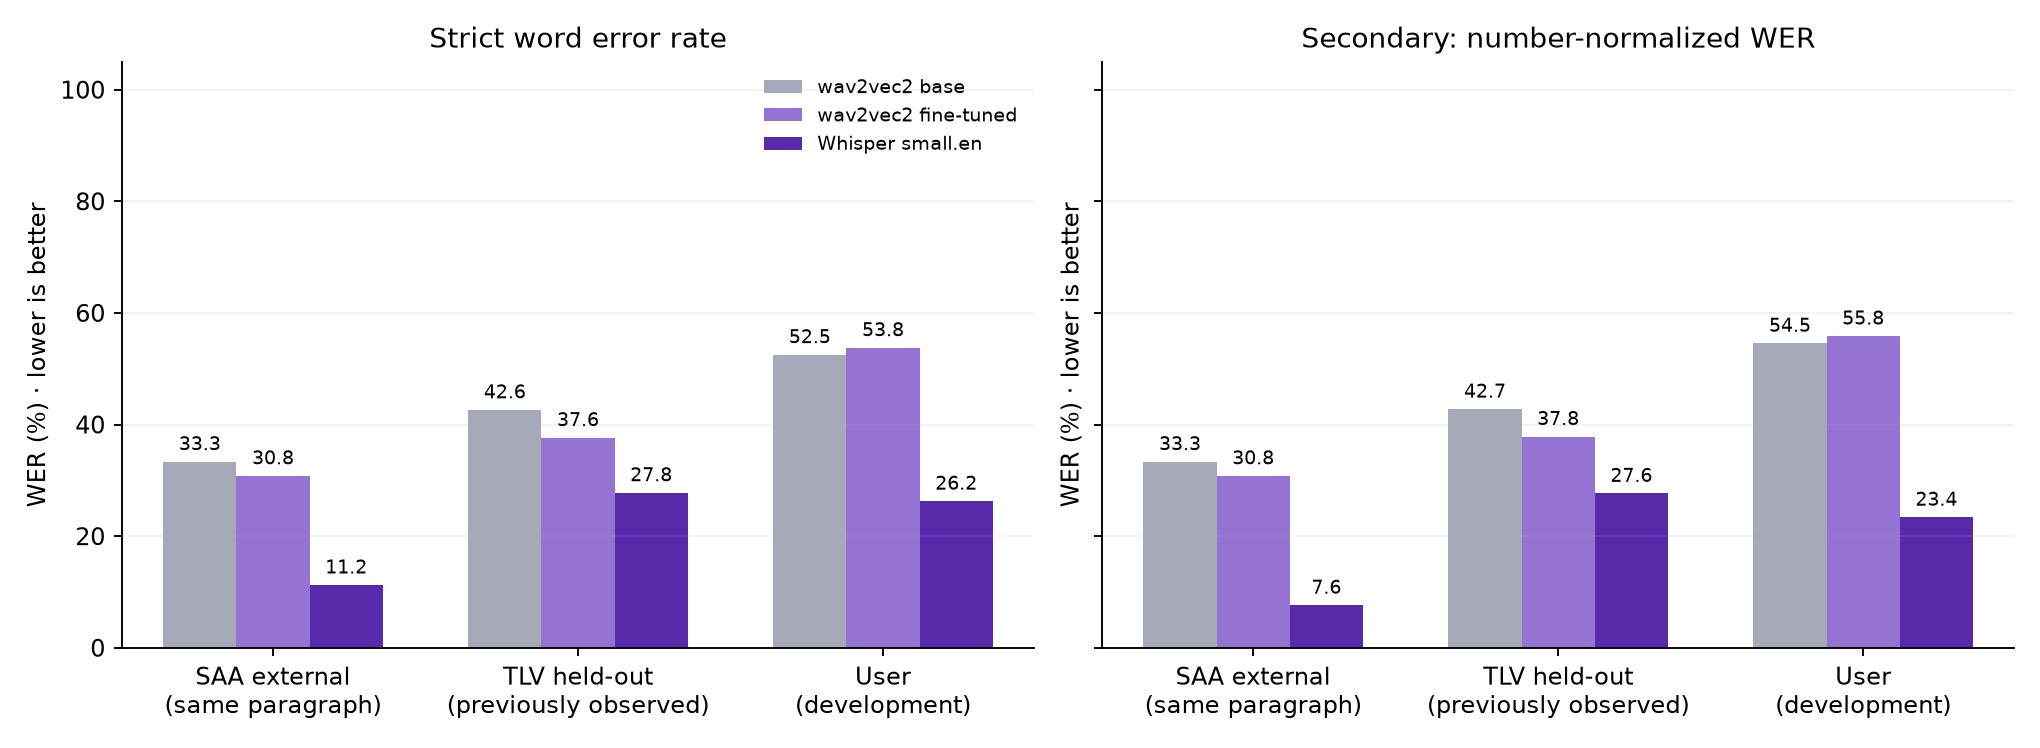

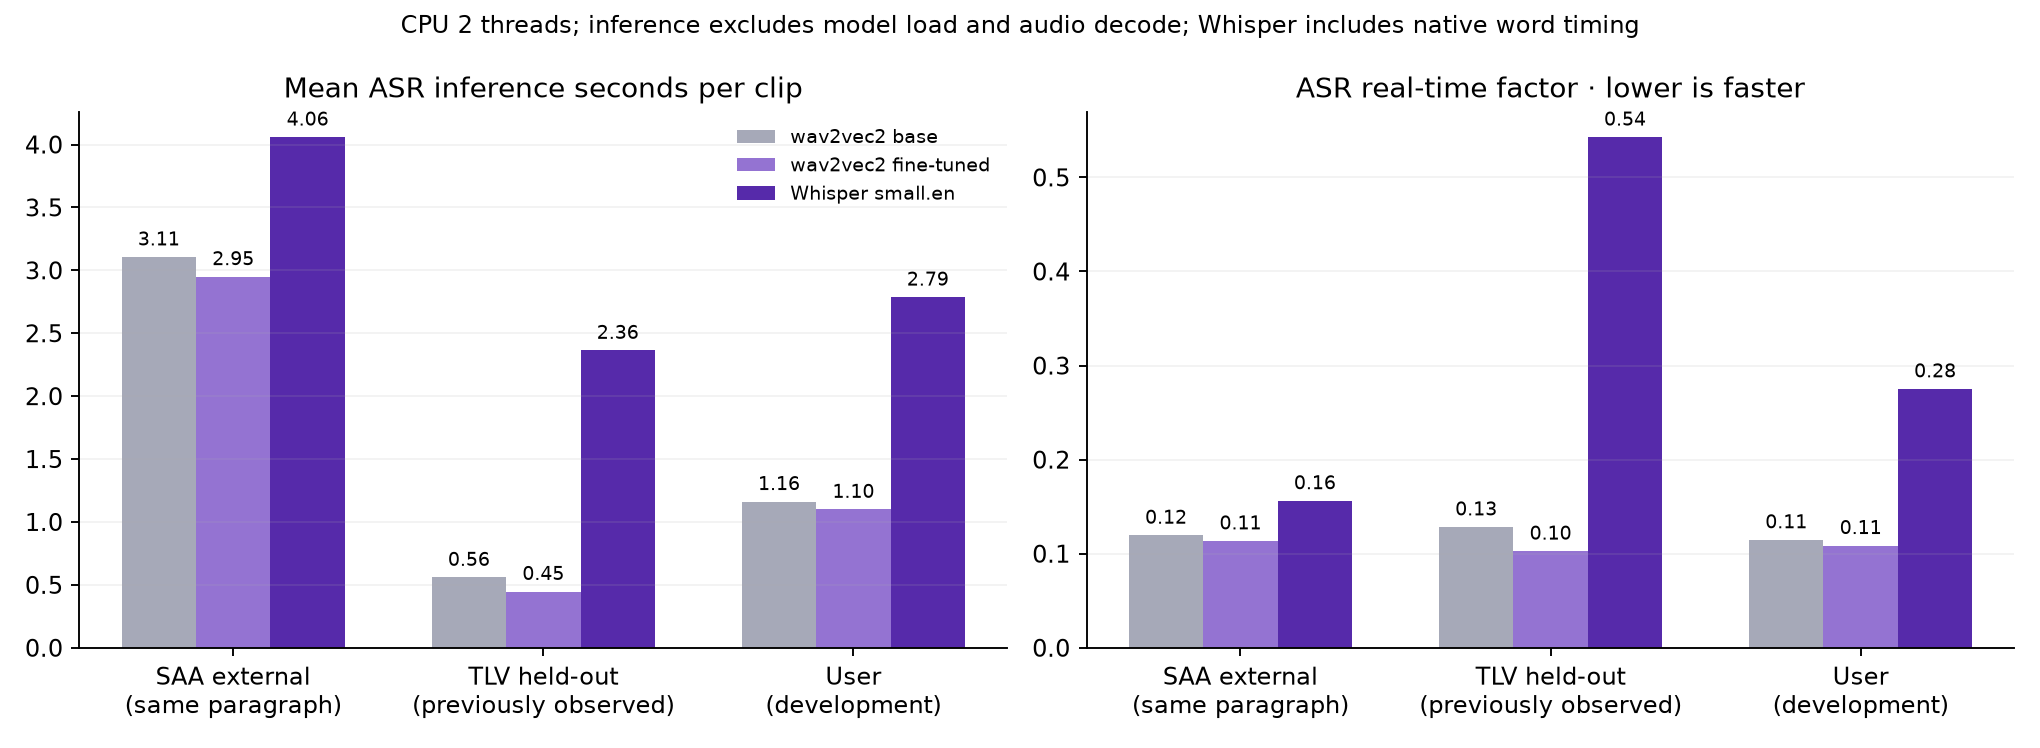

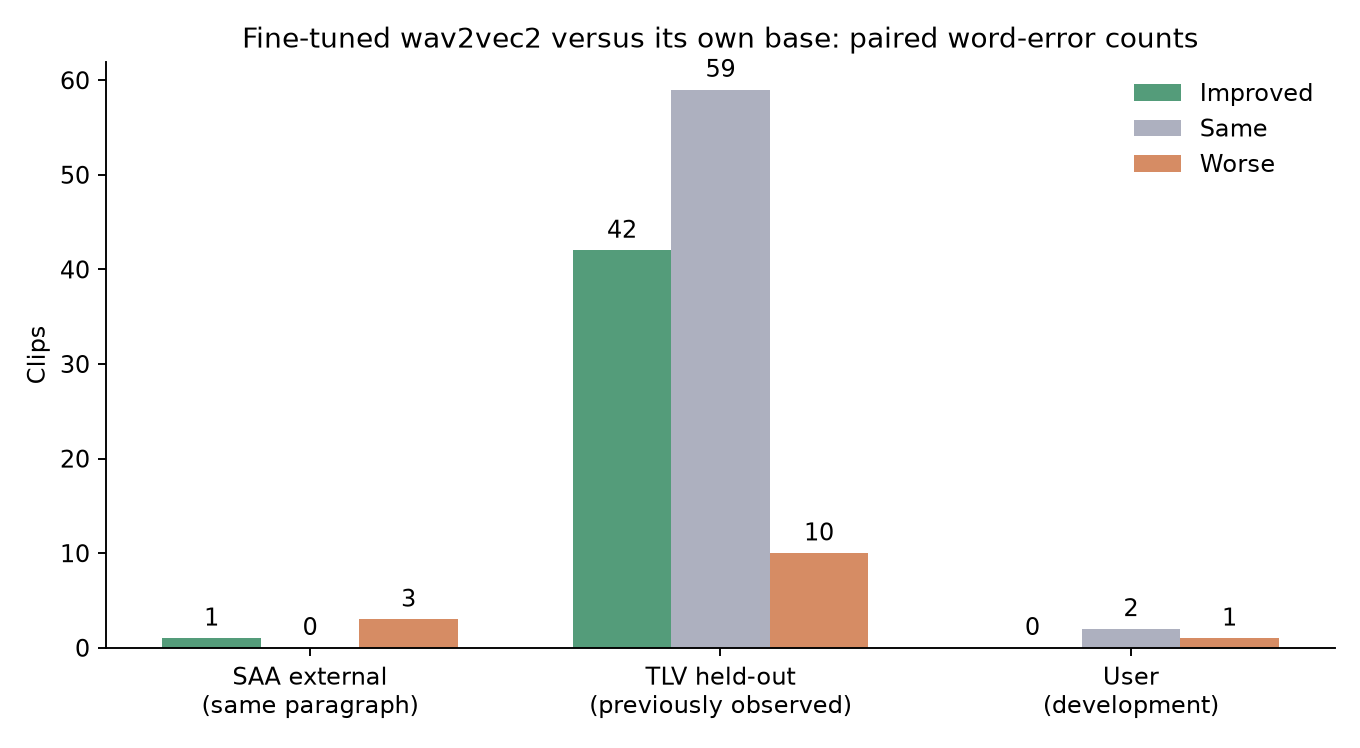

In [3]:
for filename in ("wer_by_group.png", "asr_latency.png", "fine_tuning_paired_cases.png"):
    display(Image(filename=str(OUT / filename)))

## Every recording and transcript

Whisper `raw_transcript` is scored. `production_text` additionally spells a small set of unambiguous cardinal numbers for the pronunciation dictionary.

In [4]:
per_case = pd.DataFrame(case_rows(bundle))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(per_case[["id", "group", "reference", "model", "raw_transcript", "production_text", "word_errors", "reference_words", "wer", "number_normalized_wer", "inference_sec"]])

,id,group,reference,model,raw_transcript,production_text,word_errors,reference_words,wer,number_normalized_wer,inference_sec
0,TLV-arctic_a0018,tlv_previously_observed_heldout,There was a change now,wav2vec2-base-960h,THERE WERE CHANKS NOW,THERE WERE CHANKS NOW,3,5,0.600000,0.600000,0.297
1,TLV-arctic_a0018,tlv_previously_observed_heldout,There was a change now,wav2vec2-vi-en-v1,THERE WERE A CHANGS NOW,THERE WERE A CHANGS NOW,2,5,0.400000,0.400000,0.281
2,TLV-arctic_a0018,tlv_previously_observed_heldout,There was a change now,whisper-small.en,There were a chance now.,There were a chance now.,2,5,0.400000,0.400000,2.390
3,TLV-arctic_a0024,tlv_previously_observed_heldout,It was my reports from the north which chiefly induced people to buy,wav2vec2-base-960h,HIS WORE MY REPORTS FROM THE NOTH WITH CHIF FLY INDUCED PEIPO ON TO BY,HIS WORE MY REPORTS FROM THE NOTH WITH CHIF FLY INDUCED PEIPO ON TO BY,9,13,0.692308,0.692308,0.687
4,TLV-arctic_a0024,tlv_previously_observed_heldout,It was my reports from the north which chiefly induced people to buy,wav2vec2-vi-en-v1,THIS WASE MY REPORTS FROM THE NORTH WITH CHIEF FLY INDUCED PEOPLE INTO BY,THIS WASE MY REPORTS FROM THE NORTH WITH CHIEF FLY INDUCED PEOPLE INTO BY,7,13,0.538462,0.538462,0.704
5,TLV-arctic_a0024,tlv_previously_observed_heldout,It was my reports from the north which chiefly induced people to buy,whisper-small.en,It's Walmart reports from the north with cheap fly induced people to buy.,It's Walmart reports from the north with cheap fly induced people to buy.,6,13,0.461538,0.461538,2.594
6,TLV-arctic_a0026,tlv_previously_observed_heldout,It occurred to me that there would have to be an accounting,wav2vec2-base-960h,IS A CORRENT TO ME THAT THERE WOULD HAVE TO BE AN ACCOUNTING,IS A CORRENT TO ME THAT THERE WOULD HAVE TO BE AN ACCOUNTING,3,12,0.250000,0.250000,0.437
7,TLV-arctic_a0026,tlv_previously_observed_heldout,It occurred to me that there would have to be an accounting,wav2vec2-vi-en-v1,IS A CURRENT TO ME THAT THERE WOULD HAVE TO BE AN ACCOUNTING,IS A CURRENT TO ME THAT THERE WOULD HAVE TO BE AN ACCOUNTING,3,12,0.250000,0.250000,0.438
8,TLV-arctic_a0026,tlv_previously_observed_heldout,It occurred to me that there would have to be an accounting,whisper-small.en,is accurate to mean that there would have to be an accounting.,is accurate to mean that there would have to be an accounting.,3,12,0.250000,0.250000,2.563
9,TLV-arctic_a0027,tlv_previously_observed_heldout,To my surprise he began to show actual enthusiasm in my favor,wav2vec2-base-960h,TO MY SURPRISE HE BEGAN TO SHOW ACTO ENTHUSIASM IN MY FAVOR,TO MY SURPRISE HE BEGAN TO SHOW ACTO ENTHUSIASM IN MY FAVOR,1,12,0.083333,0.083333,0.485


## Listen to three fixed examples

Audio is embedded from the frozen local source files. Examples are selected by ID rather than chosen for favourable scores.

In [5]:
examples = [manifest["cases"][0]["id"], "user-stella", "user-road"]
for identifier in examples:
    case = next(item for item in manifest["cases"] if item["id"] == identifier)
    display(Markdown(f"### {identifier}\n**Reference:** {case['reference_text']}"))
    display(Audio(filename=str(ROOT / case["audio"]), embed=True))
    display(per_case.loc[per_case.id == identifier, ["model", "raw_transcript", "wer", "inference_sec"]])

### TLV-arctic_a0018
**Reference:** There was a change now

,model,raw_transcript,wer,inference_sec
0,wav2vec2-base-960h,THERE WERE CHANKS NOW,0.6,0.297
1,wav2vec2-vi-en-v1,THERE WERE A CHANGS NOW,0.4,0.281
2,whisper-small.en,There were a chance now.,0.4,2.390


### user-stella
**Reference:** Please call Stella. Ask her to bring these things with her from the store: Six spoons of fresh snow peas, five thick slabs of blue cheese, and maybe a snack for her brother Bob. We also need a small plastic snake and a big toy frog for the kids. She can scoop these things into three red bags, and we will go meet her Wednesday at the train station.

,model,raw_transcript,wer,inference_sec
345,wav2vec2-base-960h,PLACALL TELLAR ASK HER TO BRING THE THINGS WIT...,0.434783,2.812
346,wav2vec2-vi-en-v1,PLACOLL TELLAR ASKD HER TO BRING THE THINGS WI...,0.434783,2.641
347,whisper-small.en,Please call Stella. Ask her to bring lee thing...,0.159420,3.891


### user-road
**Reference:** End of the road for some players

,model,raw_transcript,wer,inference_sec
348,wav2vec2-base-960h,AND THOU THEYLL LO THE FOR SAMUN PLAY ARMS,1.142857,0.406
349,wav2vec2-vi-en-v1,AND THOUG THEY LO THE FOR SAMON PLAY ARMS,1.142857,0.375
350,whisper-small.en,And also load for some players.,0.571429,2.250


## Provenance and limits

TLV: one previously observed held-out speaker. SAA: four speakers reading one shared paragraph. User files: development cases. Corpus/user prompts are not verified realized-word annotations. Whisper's pretraining overlap is unknown. WER does not measure pronunciation diagnosis or Qwen dialogue quality.

In [6]:
display(Markdown("**Runtime and model loading:**"))
display(pd.DataFrame(results["runtime"]).T)
display(Markdown("**Split audit:**"))
display(manifest["split_audit"])
display(Markdown("**Model files and SHA256:**"))
display(manifest["models"])
if bundle["training"]:
    training = bundle["training"]
    display({"training_dataset": training.get("dataset"), "configuration": training.get("config"),
             "base_sha256": training.get("base_sha256"), "trained_sha256": training.get("results", {}).get("trained_sha256")})
    display(Markdown("Historical training-log evaluation used GPU BF16; this paired rerun uses CPU FP32 and current strict tokenization. Small WER differences from old logs are not additional training. Original logs are preserved."))
display(Markdown("Fine-tuning improvement is evaluated against the same wav2vec2 base. Comparing against Whisper tests a separate pretrained model and decoding configuration; it does not show that fine-tuning had no benefit."))

**Runtime and model loading:**

,load_attempts,rss_before_unload_mib,rss_after_unload_mib
wav2vec2-base-960h,"[{'load_sec': 2.3910000000032596, 'rss_after_l...",991.152344,797.921875
wav2vec2-vi-en-v1,"[{'load_sec': 0.0629999999946449, 'rss_after_l...",1217.578125,857.488281
whisper-small.en,"[{'load_sec': 4.0, 'rss_after_load_mib': 1189....",1221.492188,890.296875


**Split audit:**

{'passed': True,
 'train_validation_speaker_id_overlap': [],
 'train_validation_audio_sha256_overlap': [],
 'train_validation_utterance_id_overlap': [],
 'train_validation_normalized_prompt_overlap': [],
 'train_test_speaker_id_overlap': [],
 'train_test_audio_sha256_overlap': [],
 'train_test_utterance_id_overlap': [],
 'train_test_normalized_prompt_overlap': [],
 'validation_test_speaker_id_overlap': [],
 'validation_test_audio_sha256_overlap': [],
 'validation_test_utterance_id_overlap': [],
 'validation_test_normalized_prompt_overlap': [],
 'counts': {'train': 2445, 'validation': 104, 'test': 111},
 'speakers': {'train': ['ABA',
   'ASI',
   'BWC',
   'EBVS',
   'ERMS',
   'HKK',
   'HQTV',
   'MBMPS',
   'NCC',
   'RRBI',
   'SKA',
   'SVBI',
   'THV',
   'YBAA',
   'YDCK'],
  'validation': ['PNV'],
  'test': ['TLV']},
 'duplicate_evaluation_audio_groups': [],
 'evaluation_vs_training_validation_audio_overlap': []}

**Model files and SHA256:**

{'wav2vec2-base-960h': {'path': 'models/pretrained/wav2vec2-base-960h',
  'files': {'model.safetensors': {'path': 'models/pretrained/wav2vec2-base-960h/model.safetensors',
    'bytes': 377607901,
    'sha256': '8aa76ab2243c81747a1f832954586bc566090c83a0ac167df6f31f0fa917d74a'},
   'config.json': {'path': 'models/pretrained/wav2vec2-base-960h/config.json',
    'bytes': 1673,
    'sha256': '4af3c15b370eddc09086a83c85c738c1941b0dea6e016ae46981e98bd9ff660e'},
   'tokenizer_config.json': {'path': 'models/pretrained/wav2vec2-base-960h/tokenizer_config.json',
    'bytes': 163,
    'sha256': 'dc790594f5bc351a4311c6624f40acd95850d4aaf2a5cb3c656c9b610720b608'},
   'vocab.json': {'path': 'models/pretrained/wav2vec2-base-960h/vocab.json',
    'bytes': 291,
    'sha256': '19727f8944fe6459fc3f240ae2c198395b740f6a029bd23e06656266b83bcf64'},
   'preprocessor_config.json': {'path': 'models/pretrained/wav2vec2-base-960h/preprocessor_config.json',
    'bytes': 167,
    'sha256': '2a1775f2e91be2868ca42121

{'training_dataset': {'dataset': 'L2-ARCTIC v5.0, full scripted Vietnamese transcripts + source replay',
  'indexed_counts': {'HQTV': 1132,
   'THV': 1132,
   'PNV': 1132,
   'TLV': 1132,
   'source': 1949},
  'excluded_counts': {'speaker_prompt_holdout': 2806,
   'long_train_utterance': 6},
  'seed': 42,
  'split_policy': 'Speaker-disjoint and normalized-prompt-disjoint; fixed SHA256 prompt buckets 80/10/10.',
  'train_speakers': ['HQTV', 'THV'],
  'validation_speakers': ['PNV'],
  'test_speakers': ['TLV'],
  'source_replay_count': 611,
  'source_replay_candidates': 1616,
  'labels': 'Corpus orthographic English transcripts; not gold realized-word annotations.',
  'license': 'CC BY-NC 4.0; research use',
  'parts': {'train': {'count': 2445,
    'hours': 2.494734265558075,
    'max_seconds': 7.97795918367347,
    'sha256': '87f57a3d749eae1086d29b1560b82329579bbdf4d7b6e46c6fee16f1a6f40845'},
   'validation': {'count': 104,
    'hours': 0.10382064121945074,
    'max_seconds': 6.954761904

Historical training-log evaluation used GPU BF16; this paired rerun uses CPU FP32 and current strict tokenization. Small WER differences from old logs are not additional training. Original logs are preserved.

Fine-tuning improvement is evaluated against the same wav2vec2 base. Comparing against Whisper tests a separate pretrained model and decoding configuration; it does not show that fine-tuning had no benefit.